# The Fast Fourier Transform

The Fourier transform takes a signal in **time** (or space) and tells you which **frequencies** are in it, and how much of each.

| | time domain $x_n$ | frequency domain $X_k$ |
|---|---|---|
| what you see | a wiggly signal | a few sharp spikes |
| go there | `irfft(X)` | `rfft(x)` |

- The **DFT** (Discrete Fourier Transform) is the formula.
- The **FFT** (Fast Fourier Transform) is a fast algorithm for the same formula.

Two examples: **music** (find the notes in a noisy chord, then remove the noise) and **images** (compress a photo). The notebook needs `rocks.jpg` and `bridge.jpg` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import rfft, irfft, rfftfreq, fft2, ifft2, fftshift

## 1. The formula

For $N$ samples $x_0, \dots, x_{N-1}$:
$$ X_k = \sum_{n=0}^{N-1} x_n \, e^{-2\pi i\, k n / N}, \qquad k = 0, \dots, N-1. $$

**The Fourier matrix.** This is a matrix times a vector, $X = W x$, with
$$ W_{kn} = \omega^{kn}, \qquad \omega = e^{-2\pi i / N}. $$
$\omega$ is a point on the unit circle, $1/N$ of a turn round. Row $k$ of $W$ goes round the circle $k$ times: it is **a wave of frequency $k$**. So $X_k$ is the dot product of the signal with wave $k$: it measures *how much the signal looks like that wave*.

For $N = 4$, $\omega = -i$:
$$ W = \begin{pmatrix} 1 & 1 & 1 & 1 \\ 1 & -i & -1 & i \\ 1 & -1 & 1 & -1 \\ 1 & i & -1 & -i \end{pmatrix} $$
Row 0 adds up the samples (the average level). Row 2 flips sign every step, the fastest wiggle 4 samples can show.

**Going back.** The rows of $W$ are perpendicular to each other, so $W^{-1} = \frac{1}{N}\overline{W}$: flip the sign in the exponent and divide by $N$. That is the inverse FFT.

## 2. Why "fast"? The cost

Multiplying by the $N \times N$ matrix $W$ costs $N^2$ operations.

**The trick** (Cooley and Tukey, 1965). Split the sum into **even** $n$ and **odd** $n$. Each half is a DFT of half the size. Call them $E$ and $O$:
$$ X_k = E_k + \omega^{k} O_k, \qquad X_{k+N/2} = E_k - \omega^{k} O_k, \qquad k = 0, \dots, N/2 - 1. $$

So one DFT of size $N$ = two of size $N/2$ plus $N$ cheap steps. Keep halving: $\log_2 N$ levels with $N$ work each, so $N \log_2 N$ in total.

| $N$ | $N^2$ (matrix) | $N \log_2 N$ (FFT) |
|---|---|---|
| 1,024 | about 1 million | about 10 thousand |
| 1,048,576 (a one-megapixel photo) | about $10^{12}$ | about 21 million |

## 3. A first look

A signal made of two sine waves: one goes up and down 4 times over the window, the other 8 times.

For a **real** signal we use `rfft`. It returns complex numbers $X_k$ for $k = 0, 1, \dots, N/2$. Their size `np.abs(X)` says how much of frequency $k$ is in the signal. For a sine of amplitude 1 the peak has height $N/2$, so `2 * np.abs(X) / N` gives the amplitude.

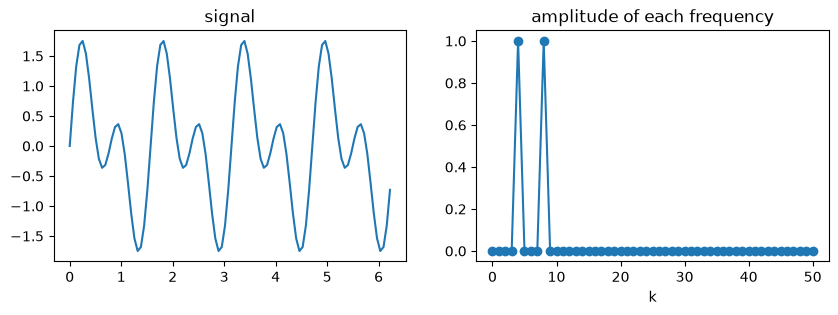

back again with irfft? True


In [2]:
N = 100
x = np.linspace(0, 2 * np.pi, N, endpoint=False)
f = np.sin(4 * x) + np.sin(8 * x)

X = rfft(f)
amp = 2 * np.abs(X) / N

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].plot(x, f)
axs[0].set_title("signal")
axs[1].plot(amp, "o-")
axs[1].set_title("amplitude of each frequency")
axs[1].set_xlabel("k")
plt.show()

print("back again with irfft?", np.allclose(irfft(X, n=N), f))

Two spikes of height 1, at $k = 4$ and $k = 8$: exactly the two sine waves.

## 4. Music: find the notes

A chord of three notes is played for half a second, sampled at $f_s = 8000$ samples per second, with loud noise on top. In the wave itself you can't see the notes.

`rfftfreq(N, d=1/fs)` gives the frequency in Hz of each entry of `rfft`. The spacing between them is $f_s / N$ Hz.

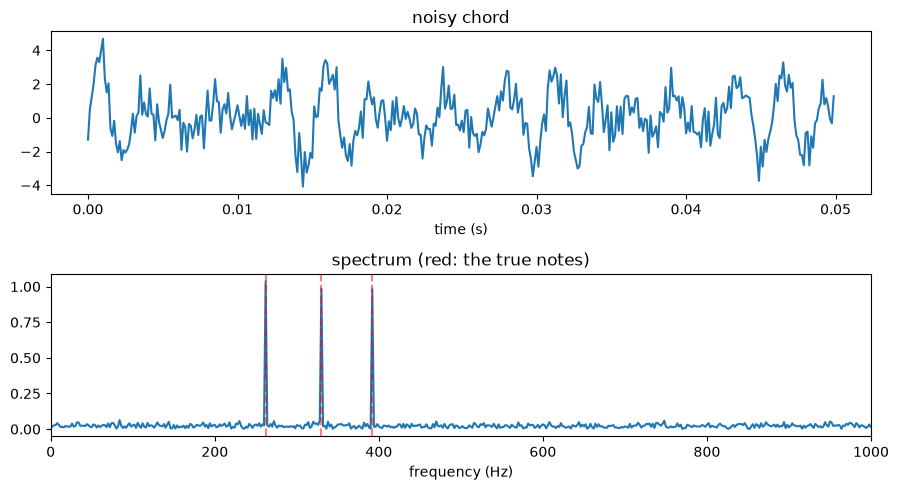

frequencies found: [262. 330. 392.] Hz


In [3]:
fs = 8000
t = np.arange(0, 0.5, 1 / fs)
notes = [262, 330, 392]                           # frequencies in Hz

clean = np.sin(2 * np.pi * notes[0] * t) + np.sin(2 * np.pi * notes[1] * t) + np.sin(2 * np.pi * notes[2] * t)
noisy = clean + 0.8 * np.random.randn(len(t))

X = rfft(noisy)
freqs = rfftfreq(len(t), d=1 / fs)
amp = 2 * np.abs(X) / len(t)

fig, axs = plt.subplots(2, 1, figsize=(9, 5))
axs[0].plot(t[:400], noisy[:400])
axs[0].set_title("noisy chord")
axs[0].set_xlabel("time (s)")
axs[1].plot(freqs, amp)
for note in notes:
    axs[1].axvline(note, color="red", linestyle="--", alpha=0.5)
axs[1].set_xlim(0, 1000)
axs[1].set_title("spectrum (red: the true notes)")
axs[1].set_xlabel("frequency (Hz)")
plt.tight_layout()
plt.show()

top3 = np.sort(freqs[np.argsort(amp)[-3:]])       # the 3 tallest peaks
print("frequencies found:", top3, "Hz")

The three tallest peaks sit exactly on the red lines. 262, 330 and 392 Hz are the notes C, E and G: a C major chord.

## 5. Music: remove the noise

The notes are a few tall spikes; the noise is a low, flat carpet over all frequencies. Keep the big coefficients, set the rest to zero, and go back with `irfft`.

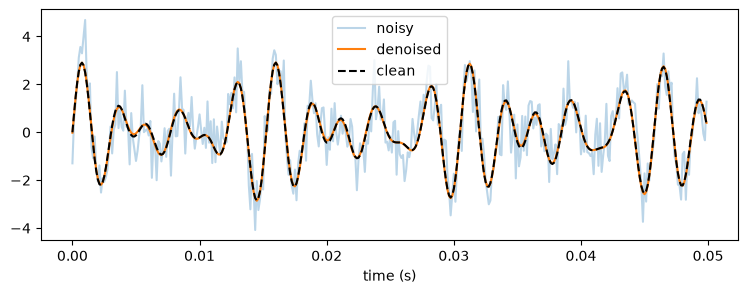

coefficients kept: 3 of 2001


In [4]:
X_kept = np.where(amp > 0.3, X, 0)                # keep only the tall spikes
denoised = irfft(X_kept, n=len(t))

plt.figure(figsize=(9, 3))
plt.plot(t[:400], noisy[:400], alpha=0.3, label="noisy")
plt.plot(t[:400], denoised[:400], label="denoised")
plt.plot(t[:400], clean[:400], "k--", label="clean")
plt.legend()
plt.xlabel("time (s)")
plt.show()

print("coefficients kept:", np.count_nonzero(X_kept), "of", len(X))

## 6. Images: compression

A grayscale image is a 2D array of numbers, one per pixel. The **2D FFT** (`fft2`) does the same in two directions: each coefficient measures how much the image looks like a stripe pattern with some direction and spacing.

- **low frequencies** (wide stripes): large shapes, the sky, the outlines of the rocks,
- **high frequencies** (narrow stripes): fine detail, texture, sharp edges.

In a photo most coefficients are tiny. **Compression:** keep only the largest few percent, set the rest to zero, and go back with `ifft2`. Only the kept coefficients need to be stored. JPEG is based on the same idea.

The spectrum is drawn with `fftshift`, which moves frequency 0 to the middle, and on a log scale, because the values range over many powers of 10. `vmin=np.median(spectrum)` starts the colour scale at the median value, so the faint half of the coefficients is drawn dark and the structure stands out.

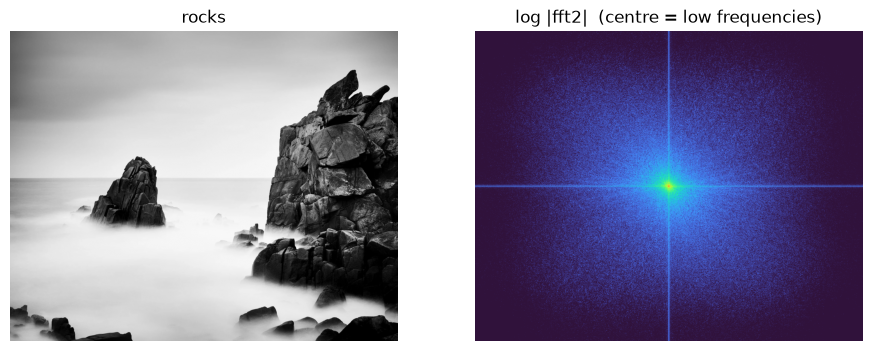

In [5]:
img = plt.imread("rocks.jpg").astype(float)      # 2D array of gray values 0 to 255
F = fft2(img)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
axs[0].imshow(img, cmap="gray")
axs[0].set_title("rocks")
spectrum = np.log(1 + np.abs(fftshift(F)))
axs[1].imshow(spectrum, cmap="turbo", vmin=np.median(spectrum))
axs[1].set_title("log |fft2|  (centre = low frequencies)")
for ax in axs:
    ax.axis("off")
plt.show()

`compress(F, keep)` keeps the largest fraction `keep` of the coefficients. `np.quantile(np.abs(F), 1 - keep)` is the size a coefficient needs to be in that top fraction.

The error is $\|\text{compressed} - \text{original}\| \,/\, \|\text{original}\|$.

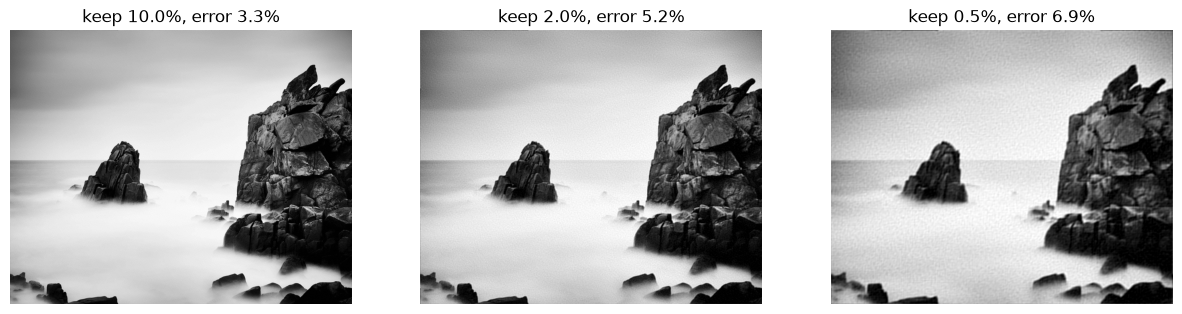

In [6]:
def compress(F, keep):
    cutoff = np.quantile(np.abs(F), 1 - keep)
    F_kept = np.where(np.abs(F) >= cutoff, F, 0)
    return ifft2(F_kept).real

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, keep in zip(axs, [0.10, 0.02, 0.005]):
    small = compress(F, keep)
    error = np.linalg.norm(small - img) / np.linalg.norm(img)
    ax.imshow(small, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"keep {keep:.1%}, error {error:.1%}")
    ax.axis("off")
plt.show()

With 2% of the coefficientsit still looks like the photo. At 0.5% the large shapes survive, but the fine texture of the rock is lost: it was carried by many small high-frequency coefficients.

### Summary

| task | code |
|---|---|
| FFT / inverse of a real signal | `rfft(x)`, `irfft(X, n=N)` |
| frequencies in Hz | `rfftfreq(N, d=1/fs)` |
| amplitude of a sine | `2 * np.abs(X) / N` |
| 2D FFT / inverse (images) | `fft2(img)`, `ifft2(F).real` |
| filter or compress | set small coefficients to 0, then invert |
| cost | matrix: $N^2$; FFT: $N \log_2 N$ |

**Where you meet the FFT:** MP3 and JPEG, Wi-Fi and 4G/5G, MRI scanners, music recognition apps.

## Exercises

**Syntax you will need:**

| task | code |
|---|---|
| time points, sampling rate `fs` | `t = np.arange(0, 0.5, 1 / fs)` |
| sine wave of frequency `f0` Hz | `np.sin(2 * np.pi * f0 * t)` |
| noise of amplitude `s` | `s * np.random.randn(len(t))` |
| plot only part of the frequency axis | `ax.set_xlim(0, 1000)` |
| spectrum | `X = rfft(x)`, `freqs = rfftfreq(len(t), d=1 / fs)` |
| amplitudes | `amp = 2 * np.abs(X) / len(t)` |
| the 3 largest peaks | `np.sort(freqs[np.argsort(amp)[-3:]])` |
| vertical line at `f0` | `ax.axvline(f0, color="red", linestyle="--")` |
| load an image | `img = plt.imread("bridge.jpg").astype(float)` |
| show an image | `ax.imshow(img, cmap="gray", vmin=0, vmax=255)` |
| hide the axes of an image | `ax.axis("off")` |
| compress | `compress(fft2(img), keep)` |
| relative error | `np.linalg.norm(small - img) / np.linalg.norm(img)` |
| several plots side by side | `fig, axs = plt.subplots(1, 3, figsize=(15, 4))` |

**Exercise 1 (find the notes of a chord).** Repeat the music example of section 4 with a different chord, step by step.

(a) **Make the signal.** Use $f_s = 8000$ samples per second and half a second of time points. Build the clean chord as the sum of three sine waves with frequencies 440, 554 and 659 Hz (the notes A, C#, E), each of amplitude 1.

(b) **Add noise.** Add random noise of amplitude 1 to the clean signal. Plot the first 400 samples of the noisy signal: can you see the notes?

(c) **Take the FFT.** Compute `rfft` of the noisy signal, the frequency of each coefficient with `rfftfreq`, and the amplitudes `2 * np.abs(X) / len(t)`.

(d) **Plot the spectrum** between 0 and 1000 Hz, with a red dashed vertical line at each of the three true frequencies. Find the frequencies of the three largest peaks and compare them with 440, 554 and 659 Hz. (The frequencies in `freqs` are 2 Hz apart, so a peak can be off by up to 1 Hz.)

(e) **Make the noise louder.** Repeat (b) to (d) with noise amplitude 2, 5, 10 and 20. From which amplitude on are the three largest peaks no longer the right ones? Run each case a few times, since the noise is different every time.

In [7]:
# Exercise 1


**Exercise 2 (compress a drawing).** Load `bridge.jpg`, a black-and-white drawing.

(a) Compress it keeping 10%, 2% and 0.5% of the coefficients. Show the three results side by side, with the error in each title.

(b) Compare the errors with those of the rocks photo. Which image is harder to compress, and why? (Hint: which frequencies do you need for a sharp jump from black to white?)

(c) Look closely at the 2% version. What do you see next to the black lines?

In [8]:
# Exercise 2
